# 1장 실습. 결정 모델: 시스템 1과 시스템 2

같은 판단을 두 방식으로 시킨다. 하나는 생성 모델(사내 GPU 의 로컬 LLM)에게 답과 확신을 JSON 으로 쓰게 하는 것이고, 다른 하나는 결정 모델(Jev)에게 선택지 위의 확률을 받는 것이다. 무엇이 다른지를 형식·정확도·확신·지연 넷으로 잰다. 마지막으로 로컬 LLM 에게 생각할 시간을 주면(thinking 모드) 무엇이 바뀌는지 본다.

| 절 | 내용 |
|---|---|
| 1.1 | 러닝 예제 하나 — 같은 문의, 두 방식의 응답 |
| 1.2 | 평가셋 400건 — 형식 어김과 정확도 |
| 1.3 | 확신의 모양 — 글로 적은 확신과 확률 |
| 1.4 | 지연 — 한 건씩, 묶어서, API |
| 1.5 | 생각하게 하면 — thinking 모드 40건 |

8장(`nb08_Evaluation.ipynb`)이 만든 `data/eval_v1.jsonl` 이 있어야 한다. 평가셋 가운데 topic(뉴스 분야 7지선다)과 positive(영화 리뷰 긍정 여부) 각 200건을 쓴다. Jev 에 약 400건(0.02달러 안팎)을 보낸다. GPU 에서 10분 안팎 걸린다.

In [1]:
import os, json, time, random
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd, matplotlib.pyplot as plt, requests
import koreanize_matplotlib  # noqa: F401
from dotenv import load_dotenv
from requests.adapters import HTTPAdapter, Retry

load_dotenv()
DATA, OUT = Path("data"), Path("out")
OUT.mkdir(exist_ok=True)
TASKS = ["topic", "entails", "positive", "similarity"]
COLOR = {"topic": "#2a78d6", "entails": "#eb6834", "positive": "#1baf7a", "similarity": "#eda100"}
pd.set_option("display.precision", 3)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
read_jsonl = lambda p: [json.loads(l) for l in Path(p).read_text(encoding="utf-8").splitlines() if l.strip()]

assert (DATA / "eval_v1.jsonl").exists(), "평가셋이 없다. nb00_Setup → nb08_Evaluation 을 먼저 실행한다"

JEV_URL = os.getenv("JEV_URL", "https://api.typesafe.ai")
http = requests.Session()
http.mount(JEV_URL, HTTPAdapter(max_retries=Retry(total=4, backoff_factor=0.5, status_forcelist=[408, 429, 500, 502, 503, 504])))

def ask(state, questions, model="jev-latest"):
    r = http.post(f"{JEV_URL}/v1/systemone", timeout=60, headers={"Authorization": f"Bearer {os.environ['TYPESAFE_API_KEY']}"},
                  json={"model": model, "state": state, "questions": questions})
    r.raise_for_status()
    return r.json() | {"_latency_s": r.elapsed.total_seconds()}

choice = lambda instructions, criteria: {"type": "choice", "instructions": instructions, "criteria": criteria}
score = lambda instructions, levels: {"type": "score", "instructions": instructions, "criteria": levels}
noul = lambda instructions, true="", false="": {"type": "noul", "instructions": instructions} | ({"criteria": {"true": true, "false": false}} if true else {})

def probs_of(answer):
    return answer.get("probabilities") or {"true": answer["noul"], "false": 1 - answer["noul"]}

def judge(item, resp):
    (task, q), = item["questions"].items()
    a = resp["answers"][task]
    pr = {str(k): float(v) for k, v in probs_of(a).items()}
    best = max(pr, key=pr.get)
    pred = {"noul": lambda: pr["true"] >= 0.5, "choice": lambda: best, "score": lambda: int(best)}[q["type"]]()
    return {"id": item["id"], "task": item["task"], "qtype": q["type"], "gold": item["gold"], "model": resp["model"],
            "pred": pred, "probs": pr, "conf": pr[best], "conf_field": a.get("confidence"), "correct": bool(pred == item["gold"]),
            "input_tokens": resp["usage"]["input_tokens"], "latency_s": resp["_latency_s"]}

def run(items, engine=lambda it: ask(it["state"], it["questions"]), workers=4):
    with ThreadPoolExecutor(workers) as ex:
        return list(ex.map(lambda it: judge(it, engine(it)), items))

arrays = lambda recs: (np.array([r["conf"] for r in recs]), np.array([r["correct"] for r in recs], float))

def ece(conf, ok, bins=15):
    idx = np.clip(np.searchsorted(np.linspace(0, 1, bins + 1), conf, side="left") - 1, 0, bins - 1)
    return float(sum(abs(conf[idx == i].mean() - ok[idx == i].mean()) * (idx == i).sum() for i in np.unique(idx)) / len(conf))

import re
RESULTS = Path("results/nb01"); RESULTS.mkdir(parents=True, exist_ok=True)
write_jsonl = lambda p, rows: Path(p).write_text("".join(json.dumps(r, ensure_ascii=False, default=str) + "\n" for r in rows), encoding="utf-8")
items = [i for i in read_jsonl(DATA / "eval_v1.jsonl") if i["task"] in ("topic", "positive")]
print("평가 항목", len(items), {t: sum(i["task"] == t for i in items) for t in ("topic", "positive")})

평가 항목 400 {'topic': 200, 'positive': 200}


In [2]:
from transformers import AutoModelForCausalLM, AutoTokenizer

LLM_MODEL = os.environ["LOCAL_LLM_MODEL"]
tok = AutoTokenizer.from_pretrained(LLM_MODEL, padding_side="left")
tok.pad_token = tok.pad_token or tok.eos_token
lm = AutoModelForCausalLM.from_pretrained(LLM_MODEL, dtype="auto", device_map="auto")

def chat_batch(prompts, max_new_tokens=256, batch_size=16, system=None):
    # 프롬프트 여럿을 묶어 generate 한 번에 보낸다(왼쪽 패딩). 서빙 엔진 없이 처리량을 내는 방법이다
    msgs = lambda p: [{"role": "system", "content": system}] * bool(system) + [{"role": "user", "content": p}]
    texts = [tok.apply_chat_template(msgs(p), tokenize=False, add_generation_prompt=True, enable_thinking=False) for p in prompts]
    outs = []
    for i in range(0, len(texts), batch_size):
        enc = tok(texts[i:i + batch_size], return_tensors="pt", padding=True).to(lm.device)
        gen = lm.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False)
        outs += tok.batch_decode(gen[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
    return [o.strip() for o in outs]

chat = lambda prompt, **kw: chat_batch([prompt], **kw)[0]
print(LLM_MODEL, "|", lm.device)

/home/josh/anaconda3/envs/pytorch/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Ignoring corrupted tree cache file /data/shared/hf/hub/models--Qwen--Qwen3.5-4B/trees/851bf6e806efd8d0a36b00ddf55e13ccb7b8cd0a.json: [Errno 13] Permission denied: '/data/shared/hf/hub/models--Qwen--Qwen3.5-4B/trees/851bf6e806efd8d0a36b00ddf55e13ccb7b8cd0a.json'
Loading weights: 100%|██████████| 426/426 [00:00<00:00, 432.40it/s]


Qwen/Qwen3.5-4B | cuda:0


## 1.1 같은 문의, 두 방식

결정 모델에는 질문(choice·score·noul)을 보내고 확률을 받는다. 생성 모델에는 같은 질문을 글로 쓰고 JSON 한 줄로 답하게 한다. 선택지 이름과 설명은 둘 다 같다.

In [3]:
TICKET_STATE = {"channel": "앱 문의",
                "message": "결제가 두 번 됐어요. 어제 저녁에 한 번만 결제했는데 카드 문자가 두 번 왔습니다. 오늘 안에 처리 안 되면 해지할게요."}
TICKET_QUESTIONS = {
    "department": choice("이 문의를 처리할 팀", {"billing": "결제, 환불, 청구 오류", "technical": "앱 오류, 로그인, 연동 문제",
                                             "account": "가입, 해지, 요금제 변경", "general": "그 밖의 문의"}),
    "urgency": score("얼마나 급하게 처리해야 하는가", ["일반 처리로 충분하다", "오늘 안에 처리해야 한다", "즉시 사람이 연락해야 한다"]),
    "churn_risk": noul("고객이 해지를 언급하거나 해지할 뜻을 보인다",
                       true="해지·탈퇴·이용 중단을 직접 말하거나 조건부로 예고한다", false="해지에 관한 언급이 없다"),
}
OPTIONS = {"choice": lambda q: q["criteria"], "score": lambda q: {str(i): v for i, v in enumerate(q["criteria"])},
           "noul": lambda q: {"true": q.get("criteria", {}).get("true", "그렇다"), "false": q.get("criteria", {}).get("false", "아니다")}}

def json_prompt(state, q):
    menu = "\n".join(f"- {k}: {v}" for k, v in OPTIONS[q["type"]](q).items())
    return (f"[판단할 대상]\n{json.dumps(state, ensure_ascii=False)}\n\n[질문]\n{q['instructions']}\n[선택지]\n{menu}\n\n"
            '다른 말 없이 JSON 한 줄로만 답하라: {"answer": "<선택지 이름>", "confidence": <답이 맞을 확률, 0과 1 사이>}')

jev = ask(TICKET_STATE, TICKET_QUESTIONS)
outs = chat_batch([json_prompt(TICKET_STATE, q) for q in TICKET_QUESTIONS.values()], max_new_tokens=48)
for (name, q), o in zip(TICKET_QUESTIONS.items(), outs):
    print(f"[{name}]\n  Jev      : {json.dumps({k: v for k, v in jev['answers'][name].items() if k != 'legend'}, ensure_ascii=False)}\n  로컬 LLM : {o}")
print(f"\nJev {jev['model']} | 입력 {jev['usage']['input_tokens']} 토큰 | {jev['_latency_s']:.3f}초")

[transformers] `causal_conv1d_fn` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.
[transformers] `chunk_gated_delta_rule` is falling back to its reference PyTorch implementation because `flash-linear-attention` is not installed. This is correct but much slower; install `flash-linear-attention` for the optimized kernel.
[transformers] `causal_conv1d_update` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.
[transformers] `fused_recurrent_gated_delta_rule` is falling back to its reference PyTorch implementation because `flash-linear-attention` is not installed. This is correct but much slower; install `flash-linear-attention` for the optimized kernel.


[department]
  Jev      : {"type": "choice", "choice": "billing", "confidence": 1.0, "probabilities": {"billing": 1.0, "technical": 0.0, "account": 0.0, "general": 0.0}}
  로컬 LLM : {"answer": "billing", "confidence": 0.95}
[urgency]
  Jev      : {"type": "score", "score": 1.06, "confidence": 0.91, "probabilities": {"0": 0.0, "1": 0.94, "2": 0.06}}
  로컬 LLM : {"answer": "2", "confidence": 0.95}
[churn_risk]
  Jev      : {"type": "noul", "noul": 0.99}
  로컬 LLM : {"answer": "true", "confidence": 0.95}

Jev jev-1.13.0 | 입력 565 토큰 | 0.212초


## 1.2 평가셋 400건: 형식과 정확도

생성 모델의 답은 글자다. 코드가 쓰려면 글자에서 답과 확신을 꺼내야 한다. `answer` 가 선택지 이름이 아니거나 `confidence` 숫자를 찾지 못하면 형식 어김으로 보고 오답으로 센다. 확신이 없으니 그 항목에는 임계값도 걸 수 없다.

In [4]:
gold_key = lambda i: {"choice": str, "noul": lambda g: str(g).lower(), "score": str}[next(iter(i["questions"].values()))["type"]](i["gold"])

def read_json_answer(item, text):
    q = next(iter(item["questions"].values()))
    ans = (re.findall(r'"answer"\s*:\s*"([^"]+)"', text) + [None])[0]
    conf = float((re.findall(r'"confidence"\s*:\s*([01](?:\.\d+)?)', text) + ["nan"])[0])
    ok_format = ans in OPTIONS[q["type"]](q) and conf == conf
    return {"id": item["id"], "task": item["task"], "raw": text, "answer": ans, "conf": conf, "format_ok": ok_format,
            "correct": ok_format and ans == gold_key(item)}

t0 = time.perf_counter()
llm_out = chat_batch([json_prompt(i["state"], next(iter(i["questions"].values()))) for i in items], max_new_tokens=48)
llm_batch_sec = (time.perf_counter() - t0) / len(items)
llm_rec = [read_json_answer(i, o) for i, o in zip(items, llm_out)]
jev_rec = run(items)
write_jsonl(RESULTS / "llm-json.records.jsonl", llm_rec); write_jsonl(RESULTS / "jev.records.jsonl", jev_rec)

L, J = pd.DataFrame(llm_rec), pd.DataFrame(jev_rec)
pd.DataFrame({t: {"로컬 LLM 형식 어김": int((~L[L.task == t]["format_ok"]).sum()), "로컬 LLM 정확도": L[L.task == t]["correct"].mean(),
                  "형식을 지킨 답의 정확도": L[(L.task == t) & L.format_ok]["correct"].mean(), "Jev 정확도": J[J.task == t]["correct"].mean()}
              for t in ("topic", "positive")}).T

,로컬 LLM 형식 어김,로컬 LLM 정확도,형식을 지킨 답의 정확도,Jev 정확도
topic,0.0,0.785,0.785,0.80
positive,0.0,0.810,0.810,0.85


In [5]:
# 형식을 어긴 답의 생김새
print(L[~L.format_ok]["raw"].str.replace("\n", " ").str[:90].value_counts().head(8).to_string())

Series([], )


## 1.3 확신의 모양

Jev 의 확신은 선택지 위 확률의 최댓값이다. 로컬 LLM 의 확신은 모델이 JSON 에 적은 숫자다. 두 확신이 몇 가지 값을 가지는지, 확신이 높은 답이 정말 더 자주 맞는지 본다.

In [6]:
Lf = L[L.format_ok]
rows = []
for name, df in [("로컬 LLM (적은 숫자)", Lf), ("Jev (확률)", J)]:
    c, y = df["conf"].to_numpy(float), df["correct"].to_numpy(float)
    rows.append({"엔진": name, "n": len(df), "서로 다른 확신 값": len(np.unique(np.round(c, 3))), "평균 확신": c.mean(), "정확도": y.mean(),
                 "확신 ≥ 0.9 의 비율": (c >= 0.9).mean(), "확신 ≥ 0.9 의 정확도": y[c >= 0.9].mean(), "확신 < 0.9 의 정확도": y[c < 0.9].mean(), "ECE": ece(c, y)})
print(pd.DataFrame(rows).set_index("엔진").T.to_string())
print("\n로컬 LLM 이 적은 확신 값의 빈도:", Lf["conf"].round(3).value_counts().head(6).to_dict())

엔진              로컬 LLM (적은 숫자)  Jev (확률)
n                      400.000   400.000
서로 다른 확신 값               4.000    55.000
평균 확신                    0.965     0.863
정확도                      0.797     0.825
확신 ≥ 0.9 의 비율            1.000     0.550
확신 ≥ 0.9 의 정확도           0.797     0.945
확신 < 0.9 의 정확도             NaN     0.678
ECE                      0.168     0.050

로컬 LLM 이 적은 확신 값의 빈도: {0.95: 255, 0.99: 84, 1.0: 46, 0.98: 15}


/tmp/ipykernel_3531917/2015489927.py:6: RuntimeWarning: Mean of empty slice
  "확신 ≥ 0.9 의 비율": (c >= 0.9).mean(), "확신 ≥ 0.9 의 정확도": y[c >= 0.9].mean(), "확신 < 0.9 의 정확도": y[c < 0.9].mean(), "ECE": ece(c, y)})
/home/josh/anaconda3/envs/pytorch/lib/python3.11/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


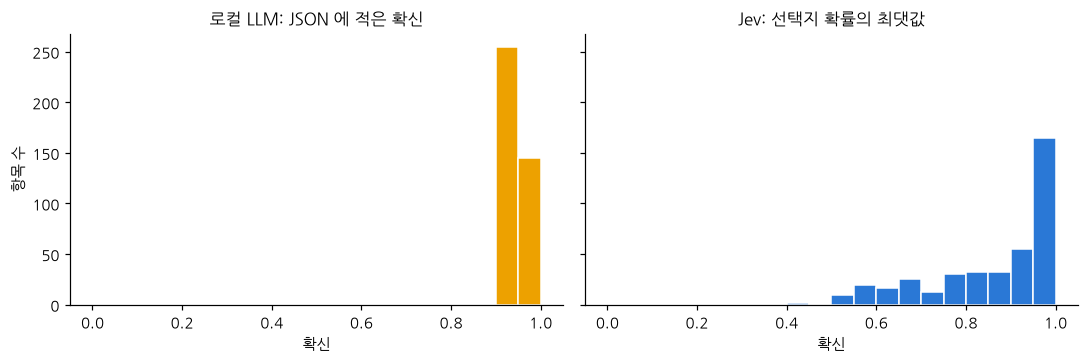

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), dpi=110, sharey=True)
for ax, (name, df, color) in zip(axes, [("로컬 LLM: JSON 에 적은 확신", Lf, "#eda100"), ("Jev: 선택지 확률의 최댓값", J, "#2a78d6")]):
    ax.hist(df["conf"], bins=np.linspace(0, 1, 21), color=color, edgecolor="white")
    ax.set_title(name, fontsize=11); ax.set_xlabel("확신")
axes[0].set_ylabel("항목 수")
fig.tight_layout(); fig.savefig(OUT / "nb01_confidence.png", bbox_inches="tight"); plt.show()

## 1.4 지연

판단은 대개 요청이 올 때마다 하나씩 한다. 로컬 LLM 을 한 건씩 부른 지연, 16건씩 묶어 부른 건당 시간, Jev API 의 지연을 나란히 놓는다.

In [8]:
one_by_one = []
for i in items[:20]:
    t0 = time.perf_counter(); chat_batch([json_prompt(i["state"], next(iter(i["questions"].values())))], max_new_tokens=48)
    one_by_one.append(time.perf_counter() - t0)
gen_tokens = [len(tok(o, add_special_tokens=False)["input_ids"]) for o in llm_out]
pd.DataFrame({"로컬 LLM 한 건씩 (20건)": {"지연 중앙값(ms)": 1000 * np.median(one_by_one), "생성 토큰 평균": np.mean(gen_tokens[:20])},
              "로컬 LLM 16건 묶음 (건당)": {"지연 중앙값(ms)": 1000 * llm_batch_sec, "생성 토큰 평균": np.mean(gen_tokens)},
              "Jev API": {"지연 중앙값(ms)": 1000 * J["latency_s"].median(), "생성 토큰 평균": 0}}).T

,지연 중앙값(ms),생성 토큰 평균
로컬 LLM 한 건씩 (20건),727.439,15.200
로컬 LLM 16건 묶음 (건당),60.845,14.998
Jev API,167.175,0.000


## 1.5 생각하게 하면: thinking 모드

Qwen3.5 는 답하기 전에 생각을 글로 풀어 쓰는 모드가 있다. 사람의 시스템 2 처럼 천천히 따져 보는 셈이다. topic 40건에 생각할 자리(최대 1,024토큰)를 주고, 생각 뒤의 답을 같은 방식으로 읽는다. 생각이 1,024토큰 안에 끝나지 않으면 답이 없으므로 형식 어김이 된다.

In [9]:
def chat_think(prompts, max_new_tokens=1024, batch_size=8):
    texts = [tok.apply_chat_template([{"role": "user", "content": p}], tokenize=False, add_generation_prompt=True, enable_thinking=True) for p in prompts]
    outs = []
    for i in range(0, len(texts), batch_size):
        enc = tok(texts[i:i + batch_size], return_tensors="pt", padding=True).to(lm.device)
        gen = lm.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False)
        outs += tok.batch_decode(gen[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
    return outs

sub = [i for i in items if i["task"] == "topic"][:40]
t0 = time.perf_counter()
think_out = chat_think([json_prompt(i["state"], next(iter(i["questions"].values()))) for i in sub])
think_sec = (time.perf_counter() - t0) / len(sub)
think_rec = [read_json_answer(i, o.partition("</think>")[2]) | {"finished": "</think>" in o, "gen_tokens": len(tok(o, add_special_tokens=False)["input_ids"])}
             for i, o in zip(sub, think_out)]
write_jsonl(RESULTS / "llm-think.records.jsonl", think_rec)
T = pd.DataFrame(think_rec)
ids = {i["id"] for i in sub}
pd.DataFrame({"생각 없이 (JSON)": {"정확도": L[L.id.isin(ids)]["correct"].mean(), "형식 어김": int((~L[L.id.isin(ids)]["format_ok"]).sum()),
                                  "생성 토큰 평균": np.mean([g for r, g in zip(llm_rec, gen_tokens) if r["id"] in ids]), "건당 시간(ms, 묶음)": 1000 * llm_batch_sec},
              "생각하고 (thinking)": {"정확도": T["correct"].mean(), "형식 어김": int((~T["format_ok"]).sum()),
                                     "생성 토큰 평균": T["gen_tokens"].mean(), "건당 시간(ms, 묶음)": 1000 * think_sec},
              "Jev": {"정확도": J[J.id.isin(ids)]["correct"].mean(), "형식 어김": 0, "생성 토큰 평균": 0, "건당 시간(ms, 묶음)": 1000 * J[J.id.isin(ids)]["latency_s"].median()}}).T

,정확도,형식 어김,생성 토큰 평균,"건당 시간(ms, 묶음)"
생각 없이 (JSON),0.850,0.0,15.250,60.845
생각하고 (thinking),0.575,16.0,896.825,5198.010
Jev,0.850,0.0,0.000,162.759


In [10]:
print("생각이 1,024토큰 안에 끝나지 않은 항목:", int((~T["finished"]).sum()), "/", len(T))
print("생각 뒤 확신 값의 빈도:", T[T.format_ok]["conf"].round(3).value_counts().head(5).to_dict())
del lm; import torch; torch.cuda.empty_cache()

생각이 1,024토큰 안에 끝나지 않은 항목: 15 / 40
생각 뒤 확신 값의 빈도: {0.95: 17, 0.99: 5, 1.0: 1, 0.98: 1}


## 정리

이 노트북이 잰 것이다. 결과 해석은 1장 본문에서 한다.

- 1.1 같은 문의에 대한 Jev 의 확률 응답과 로컬 LLM 의 JSON 응답
- 1.2 평가셋 400건에서 로컬 LLM 의 형식 어김·정확도, 형식을 지킨 답의 정확도, Jev 의 정확도 (`results/nb01/`)
- 1.3 두 엔진의 확신이 가지는 값의 수, 확신 구간별 정확도, ECE, 확신 분포 그림
- 1.4 로컬 LLM 한 건씩·묶음의 지연과 Jev API 의 지연
- 1.5 thinking 모드 40건의 정확도·형식 어김·생성 토큰·시간